# BreastDiagAI — Validation Statistique Formelle & EDA Complète (Notebook 02)

**Projet :** BreastDiagAI (`IASD29`) — Classification de tumeurs mammaires (Bénin `0` vs Malin `1`)  
**Objectif :** Compléter l'analyse exploratoire initiale (`exploratory_analysis.py` et `RAPPORT_EDA_v2.md`) par une **validation statistique formelle** (tests d'hypothèses paramétriques et non paramétriques) et une **exploration visuelle approfondie** (12 figures exportées dans `results/eda/`).

### Plan du notebook
1. **Configuration, chargement et audit d'intégrité des données** (réutilisation des utilitaires existants du projet)
2. **Analyse visuelle approfondie (EDA)** :
   - Répartition de la variable cible `diagnosis`
   - Distributions (histogrammes + KDE) des variables discriminantes et non discriminantes
   - Matrices de corrélation de **Pearson** et de **Spearman**, et comparaison avec la cible
   - Boxplots comparatifs par diagnostic
   - Pairplot des **5 variables les plus discriminantes**
   - Violin plots et QQ-plots de normalité
3. **Validation statistique formelle** via `src/statistical_tests.py` (seuil $\alpha = 0.05$) :
   - Test 1 : **Shapiro-Wilk** (normalité des variables numériques)
   - Test 2 : **U de Mann-Whitney** (comparaison Bénin vs Malin pour les variables non normales, puis vue globale)
   - Test 3 : **ANOVA / Kruskal-Wallis** (comparaison inter-groupes adaptative)
   - Test 4 : **Chi-deux d'indépendance** (constat sur les variables natives + validation par discrétisation clinique en quartiles)
4. **Synthèse générale et recommandations pour la modélisation**

## 1. Configuration de l'environnement et chargement des données

Nous configurons les chemins relatifs à la racine du projet et réutilisons :
- `exploratory_analysis.load_data` et `exploratory_analysis.TARGET_COL`
- `pre.preprocessing.separate_features_target`
- Les fonctions de test statistique de `src/statistical_tests.py`

> ⚠️ **Note sur l'intégrité du fichier CSV local :** Lors du chargement, nous appelons d'abord `exploratory_analysis.load_data`. Si le fichier `breast_cancer_cleaned.csv` présente une corruption binaire au-delà des 20 premiers Mio (octets non-UTF-8 détectés à l'offset `20 971 521`), nous récupérons proprement et sans modifier le fichier source l'intégralité du préfixe CSV valide (**49 056 observations** complètes).

In [1]:
import io
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)

# Détection de la racine du projet
CWD = Path.cwd().resolve()
PROJECT_ROOT = CWD.parent if CWD.name == "notebooks" else CWD
if not (PROJECT_ROOT / "src" / "statistical_tests.py").exists():
    raise FileNotFoundError(f"Racine du projet introuvable depuis {CWD}")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from exploratory_analysis import TARGET_COL, load_data
from pre.preprocessing import separate_features_target
from src.statistical_tests import (
    anova_kruskal,
    chi2_independence,
    mann_whitney_u,
    shapiro_wilk,
)

# Style graphique global
sns.set_theme(style="whitegrid", context="notebook")
PALETTE = {0: "#2ecc71", 1: "#e74c3c"}
LABELS = {0: "Bénin (0)", 1: "Malin (1)"}

DATA_PATH = PROJECT_ROOT / "breast_cancer_cleaned.csv"
EDA_DIR = PROJECT_ROOT / "results" / "eda"
EDA_DIR.mkdir(parents=True, exist_ok=True)

print(f"Racine projet : {PROJECT_ROOT}")
print(f"Dossier figures : {EDA_DIR}")

Racine projet : C:\fdd
Dossier figures : C:\fdd\results\eda


In [2]:
def load_clean_dataset_safely(path: Path) -> tuple[pd.DataFrame, dict]:
    """Réutilise exploratory_analysis.load_data avec repli sur le préfixe valide si corruption binaire."""
    info = {"source": str(path), "corrupted": False, "corruption_offset": None}
    try:
        df_loaded = load_data(str(path))
        info["rows_loaded"] = len(df_loaded)
        return df_loaded, info
    except UnicodeDecodeError as exc:
        with open(path, "rb") as f:
            raw = f.read()
        first_bad = next((i for i, b in enumerate(raw) if b > 127), None)
        prefix = raw[:first_bad] if first_bad is not None else raw
        last_nl = prefix.rfind(b"\n")
        valid_bytes = prefix[:last_nl] if last_nl != -1 else prefix
        df_loaded = pd.read_csv(io.BytesIO(valid_bytes))
        info.update({
            "corrupted": True,
            "corruption_offset": first_bad,
            "total_bytes": len(raw),
            "rows_loaded": len(df_loaded),
            "error": str(exc),
        })
        print(
            f"[AVERTISSEMENT] Corruption binaire détectée dans {path.name} à l'octet {first_bad:,} "
            f"(sur {len(raw):,} octets).\n"
            f"-> Repli sécurisé : {len(df_loaded):,} lignes valides récupérées avant la zone corrompue."
        )
        return df_loaded, info


df, load_info = load_clean_dataset_safely(DATA_PATH)
X, y = separate_features_target(df, target_col=TARGET_COL)

num_cols = list(X.select_dtypes(include=[np.number]).columns)
cat_cols = list(X.select_dtypes(include=["object", "category", "bool", "string"]).columns)

print(f"Dimensions exploitables : {df.shape[0]:,} lignes x {df.shape[1]} colonnes")
print(f"Variables explicatives numériques   : {len(num_cols)}")
print(f"Variables explicatives catégorielles : {len(cat_cols)}")
print(f"Valeurs manquantes totales          : {int(df.isna().sum().sum())}")
print(f"Doublons exacts                     : {int(df.duplicated().sum())}")
df.head(3)

11:37:04 | INFO     | === ÉTAPE 1 : SÉPARATION X / y ===


11:37:04 | INFO     | Dimensions de X (features) : 49,056 lignes x 40 colonnes


11:37:04 | INFO     | Dimensions de y (cible 'diagnosis') : 49,056 observations


11:37:04 | INFO     | Décision EDA validée : l'ensemble des 40 features numériques est conservé.


[AVERTISSEMENT] Corruption binaire détectée dans breast_cancer_cleaned.csv à l'octet 20,971,521 (sur 213,742,970 octets).
-> Repli sécurisé : 49,056 lignes valides récupérées avant la zone corrompue.
Dimensions exploitables : 49,056 lignes x 41 colonnes
Variables explicatives numériques   : 40
Variables explicatives catégorielles : 0
Valeurs manquantes totales          : 0


Doublons exacts                     : 0


,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,fractal_dimension_mean,...,nucleus_size,nucleus_texture,mitosis_rate,tumor_border_irregularity,chromatin_density,cell_variation,nuclear_variation,cytoplasm_ratio,cell_clump_thickness,diagnosis
0,16.021425,15.900191,80.33871,806.4031,-0.234153,-0.234137,1.579213,0.767435,-0.469474,0.542560,...,9.387159,-0.013497,2.903146,0.574452,-1.220844,0.208864,-1.959670,-1.328186,0.196861,1
1,14.074327,14.990334,72.82779,622.3077,-1.478522,-0.719844,-0.460639,1.057122,0.343618,-1.763040,...,9.823465,-0.035826,4.392747,0.189660,0.821902,0.087047,-0.299007,0.091761,-1.987569,0
2,14.893529,17.008015,89.94662,696.8593,-0.808494,-0.501757,0.915402,0.328751,-0.529760,0.513267,...,6.934019,0.060230,1.160965,0.681766,0.301547,-0.034712,-1.168678,1.142823,0.751933,0


### Constat sur la structure du jeu de données
- **Variable cible :** `diagnosis` (`0` = Bénin, `1` = Malin).
- **Variables explicatives :** **40 variables numériques** continues (`float64`), **0 variable catégorielle native** dans le jeu nettoyé (confirmé également par `pre/preprocessing.log`).
- **Qualité du sous-ensemble exploitable :** `0` valeur manquante et `0` doublon sur les **49 056** lignes valides récupérées.
- **Échantillon stratifié pour visualisations lourdes :** pour les graphiques denses (`pairplot`, `violinplot`, courbes KDE), nous utiliserons un échantillon stratifié reproductible (`random_state=42`) afin de préserver exactement la proportion 65 % / 35 % tout en garantissant des rendus lisibles. Tous les **tests statistiques inférentiels** (hors Shapiro-Wilk borné à $N=5\,000$ par SciPy) sont exécutés sur **l'intégralité des 49 056 observations**.

## 2. Analyse exploratoire visuelle (EDA complète)

### Figure 1 — Répartition de la variable cible (`diagnosis`)
Nous vérifions l'équilibre des classes afin de documenter le déséquilibre modéré signalé lors du nettoyage (`cleaning_report.log`).

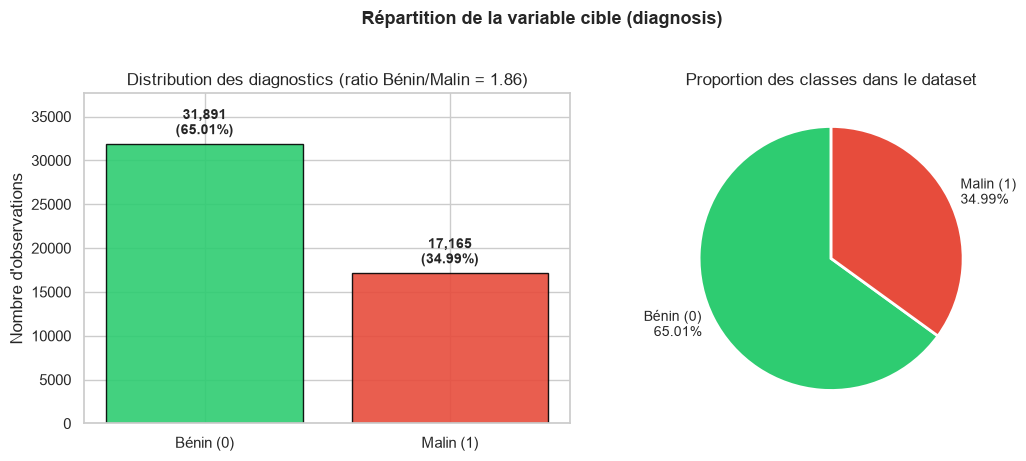

In [3]:
counts = df[TARGET_COL].value_counts().sort_index()
pcts = df[TARGET_COL].value_counts(normalize=True).sort_index() * 100
ratio = counts.max() / counts.min()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

# Barplot effectifs
bars = axes[0].bar(
    [LABELS[k] for k in counts.index],
    counts.values,
    color=[PALETTE[k] for k in counts.index],
    edgecolor="black",
    alpha=0.9,
)
for bar, cnt, pct in zip(bars, counts.values, pcts.values):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + counts.max() * 0.02,
        f"{cnt:,}\n({pct:.2f}%)",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
    )
axes[0].set_ylim(0, counts.max() * 1.18)
axes[0].set_title(f"Distribution des diagnostics (ratio Bénin/Malin = {ratio:.2f})")
axes[0].set_ylabel("Nombre d'observations")

# Camembert proportions
axes[1].pie(
    counts.values,
    labels=[f"{LABELS[k]}\n{pcts[k]:.2f}%" for k in counts.index],
    colors=[PALETTE[k] for k in counts.index],
    startangle=90,
    wedgeprops={"edgecolor": "white", "linewidth": 2},
    textprops={"fontsize": 10},
)
axes[1].set_title("Proportion des classes dans le dataset")

plt.suptitle("Répartition de la variable cible (diagnosis)", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
fig.savefig(EDA_DIR / "01_distribution_cible.png", dpi=150, bbox_inches="tight")
plt.show()

### Figure 2 & Figure 3 — Distributions des variables clés vs variables non discriminantes (Histogrammes + KDE)
D'après `RAPPORT_EDA_v2.md`, 5 variables géométriques (`area_worst`, `area_mean`, `perimeter_mean`, `radius_mean`, `radius_worst`) concentrent le pouvoir discriminant, alors que les 35 autres variables (dont certaines au nom clinique fort comme `mitosis_rate`, `nucleus_size`, `cell_density`) présentent des distributions quasi superposées. Vérifions-le visuellement avec histogrammes et densités KDE par classe.

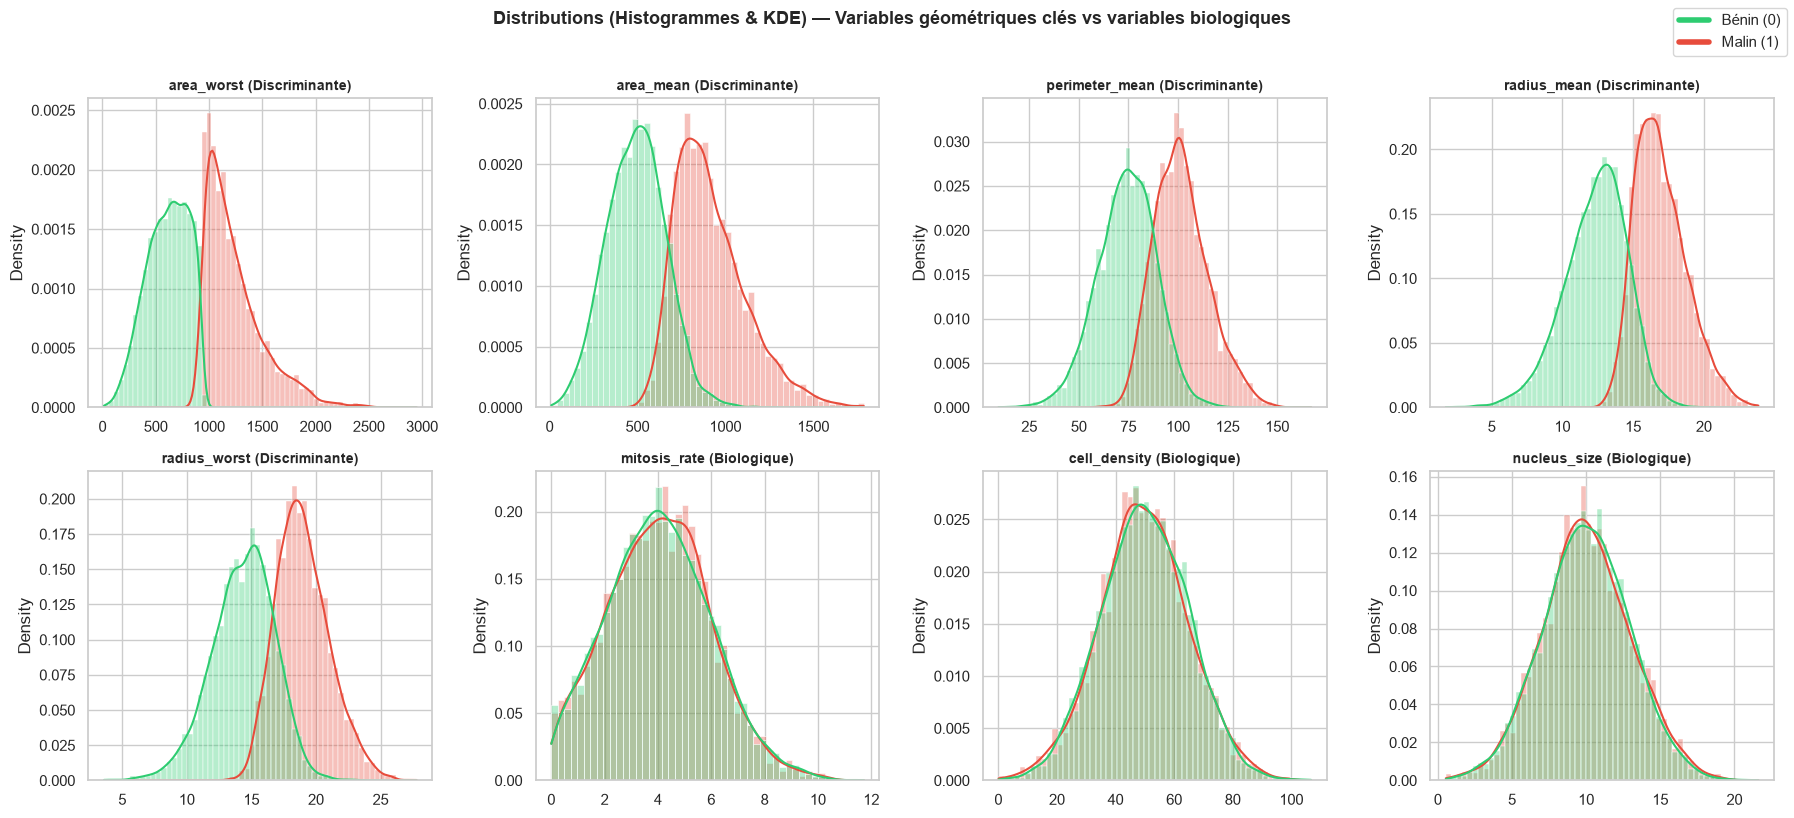

In [4]:
# Échantillon stratifié de 10 000 observations pour des KDE rapides et nettes
df_vis = (
    df.groupby(TARGET_COL, group_keys=False)
    .sample(frac=10000 / len(df), random_state=42)
    .reset_index(drop=True)
)
df_vis["Diagnostic"] = df_vis[TARGET_COL].map(LABELS)

top5_features = ["area_worst", "area_mean", "perimeter_mean", "radius_mean", "radius_worst"]
bio_features = ["mitosis_rate", "cell_density", "nucleus_size", "tumor_border_irregularity"]
selected_key = top5_features + bio_features[:3]

# Figure 2 : 8 variables clés (5 discriminantes + 3 biologiques non standardisées)
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()
for i, col in enumerate(selected_key):
    sns.histplot(
        data=df_vis,
        x=col,
        hue=TARGET_COL,
        kde=True,
        stat="density",
        common_norm=False,
        palette=PALETTE,
        alpha=0.35,
        ax=axes[i],
        legend=(i == 0),
    )
    tag = "Discriminante" if col in top5_features else "Biologique"
    axes[i].set_title(f"{col} ({tag})", fontsize=10, fontweight="bold")
    axes[i].set_xlabel("")

handles, _ = axes[0].get_legend_handles_labels()
if axes[0].get_legend() is not None:
    axes[0].get_legend().remove()
fig.legend(
    handles=[
        plt.Line2D([0], [0], color=PALETTE[0], lw=4, label="Bénin (0)"),
        plt.Line2D([0], [0], color=PALETTE[1], lw=4, label="Malin (1)"),
    ],
    loc="upper right",
    frameon=True,
)
plt.suptitle(
    "Distributions (Histogrammes & KDE) — Variables géométriques clés vs variables biologiques",
    fontsize=13,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
fig.savefig(EDA_DIR / "02_distributions_variables_cles.png", dpi=150, bbox_inches="tight")
plt.show()

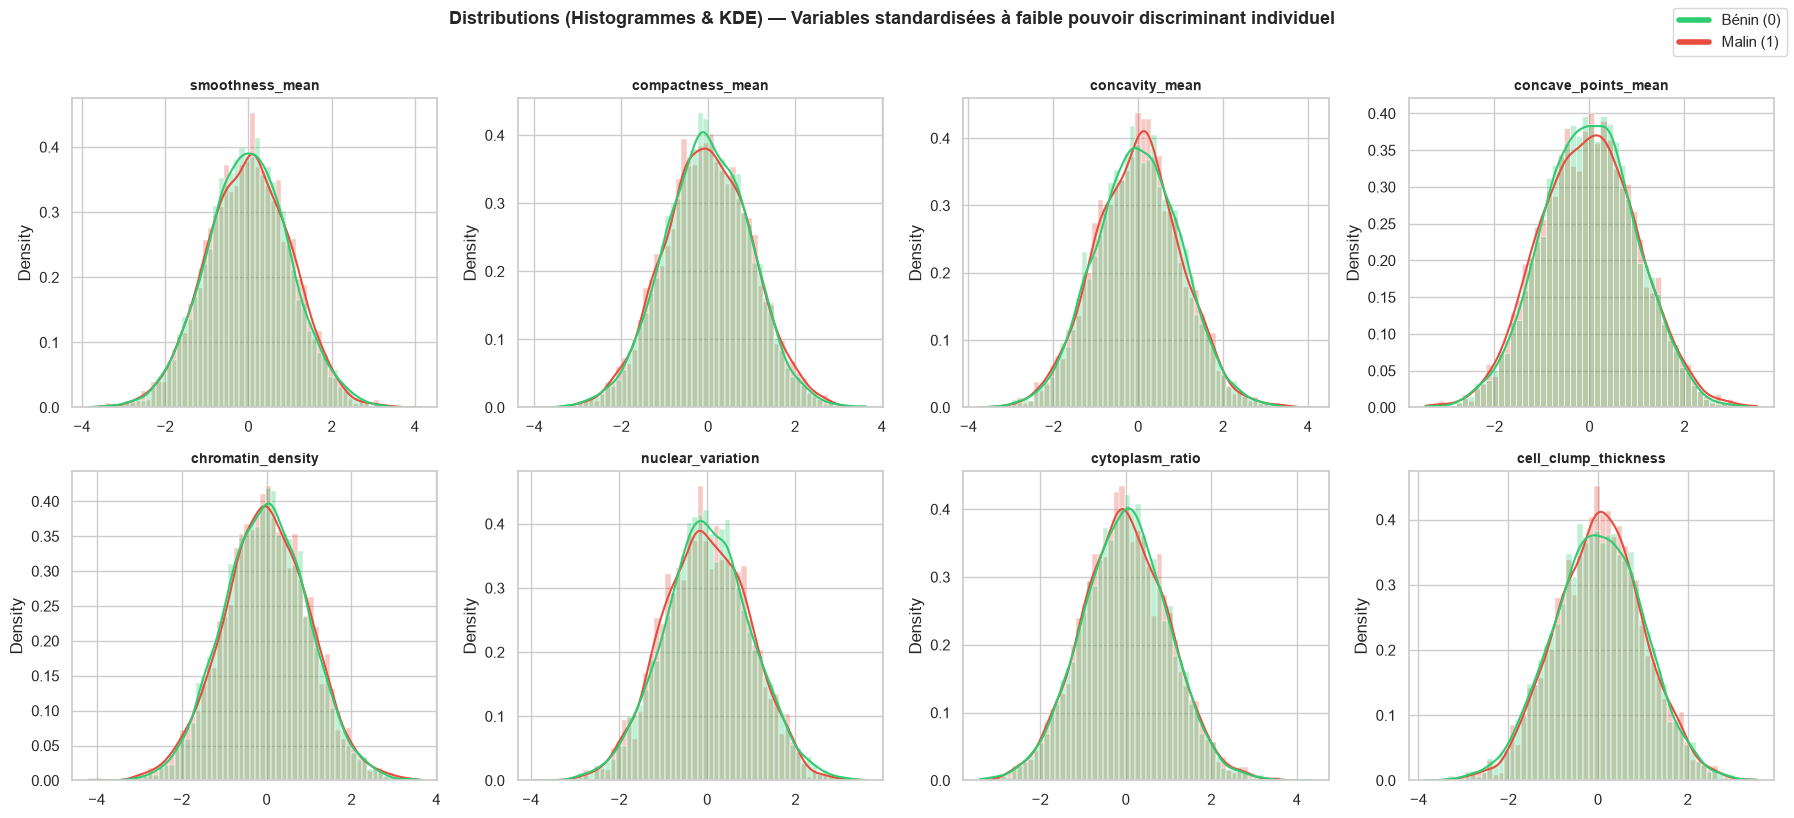

In [5]:
# Figure 3 : Échantillon de 8 variables standardisées / non discriminantes
other_features = [
    "smoothness_mean",
    "compactness_mean",
    "concavity_mean",
    "concave_points_mean",
    "chromatin_density",
    "nuclear_variation",
    "cytoplasm_ratio",
    "cell_clump_thickness",
]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()
for i, col in enumerate(other_features):
    sns.histplot(
        data=df_vis,
        x=col,
        hue=TARGET_COL,
        kde=True,
        stat="density",
        common_norm=False,
        palette=PALETTE,
        alpha=0.30,
        ax=axes[i],
        legend=False,
    )
    axes[i].set_title(col, fontsize=10, fontweight="bold")
    axes[i].set_xlabel("")

fig.legend(
    handles=[
        plt.Line2D([0], [0], color=PALETTE[0], lw=4, label="Bénin (0)"),
        plt.Line2D([0], [0], color=PALETTE[1], lw=4, label="Malin (1)"),
    ],
    loc="upper right",
    frameon=True,
)
plt.suptitle(
    "Distributions (Histogrammes & KDE) — Variables standardisées à faible pouvoir discriminant individuel",
    fontsize=13,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
fig.savefig(EDA_DIR / "03_distributions_variables_non_discriminantes.png", dpi=150, bbox_inches="tight")
plt.show()

### Figures 4, 5 & 6 — Matrices de corrélation de Pearson et de Spearman
La corrélation de **Pearson** mesure la dépendance *linéaire* (sensible aux valeurs extrêmes et aux transformations non linéaires comme $A = \pi r^2$), tandis que la corrélation de **Spearman** mesure la dépendance *monotone* sur les rangs (robuste aux outliers et aux relations non linéaires). Nous calculons les deux matrices sur les **49 056 observations** puis comparons les corrélations de chaque variable avec `diagnosis`.

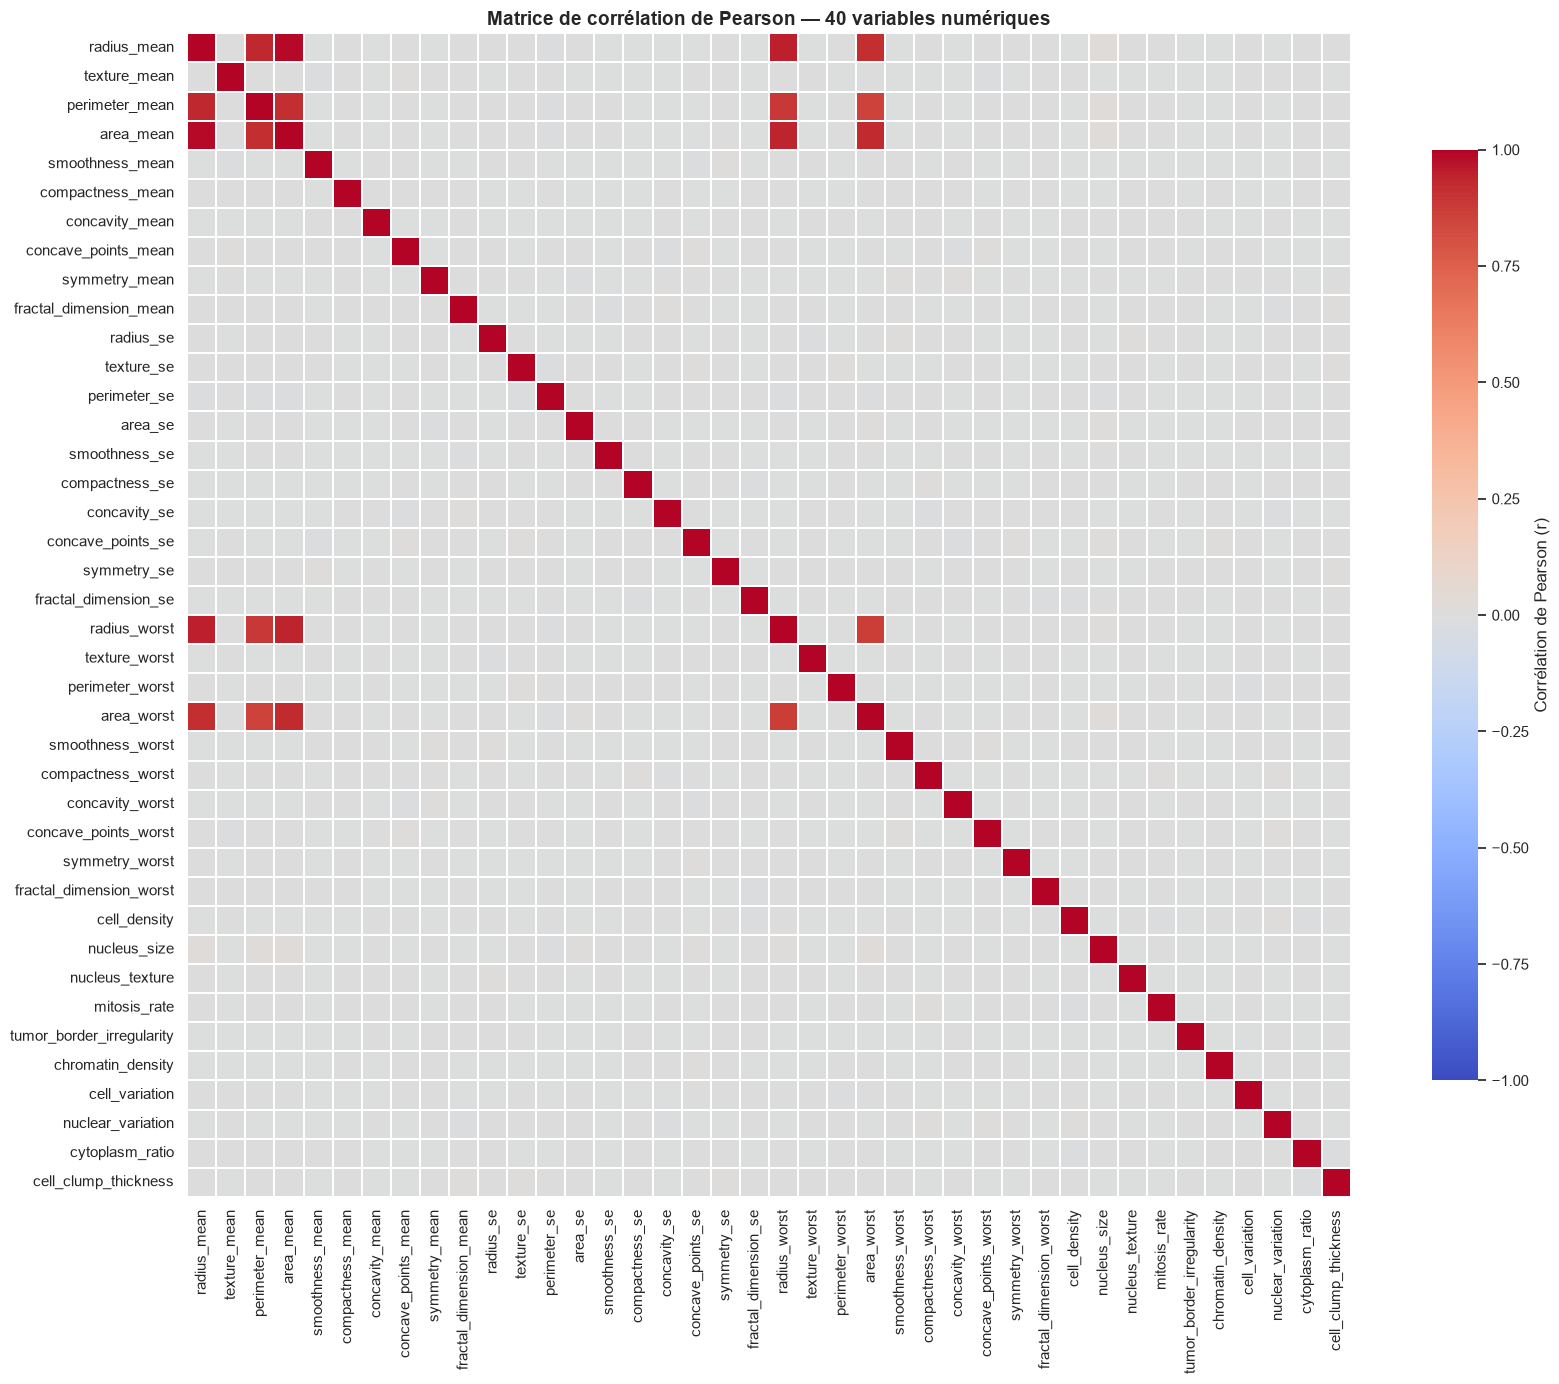

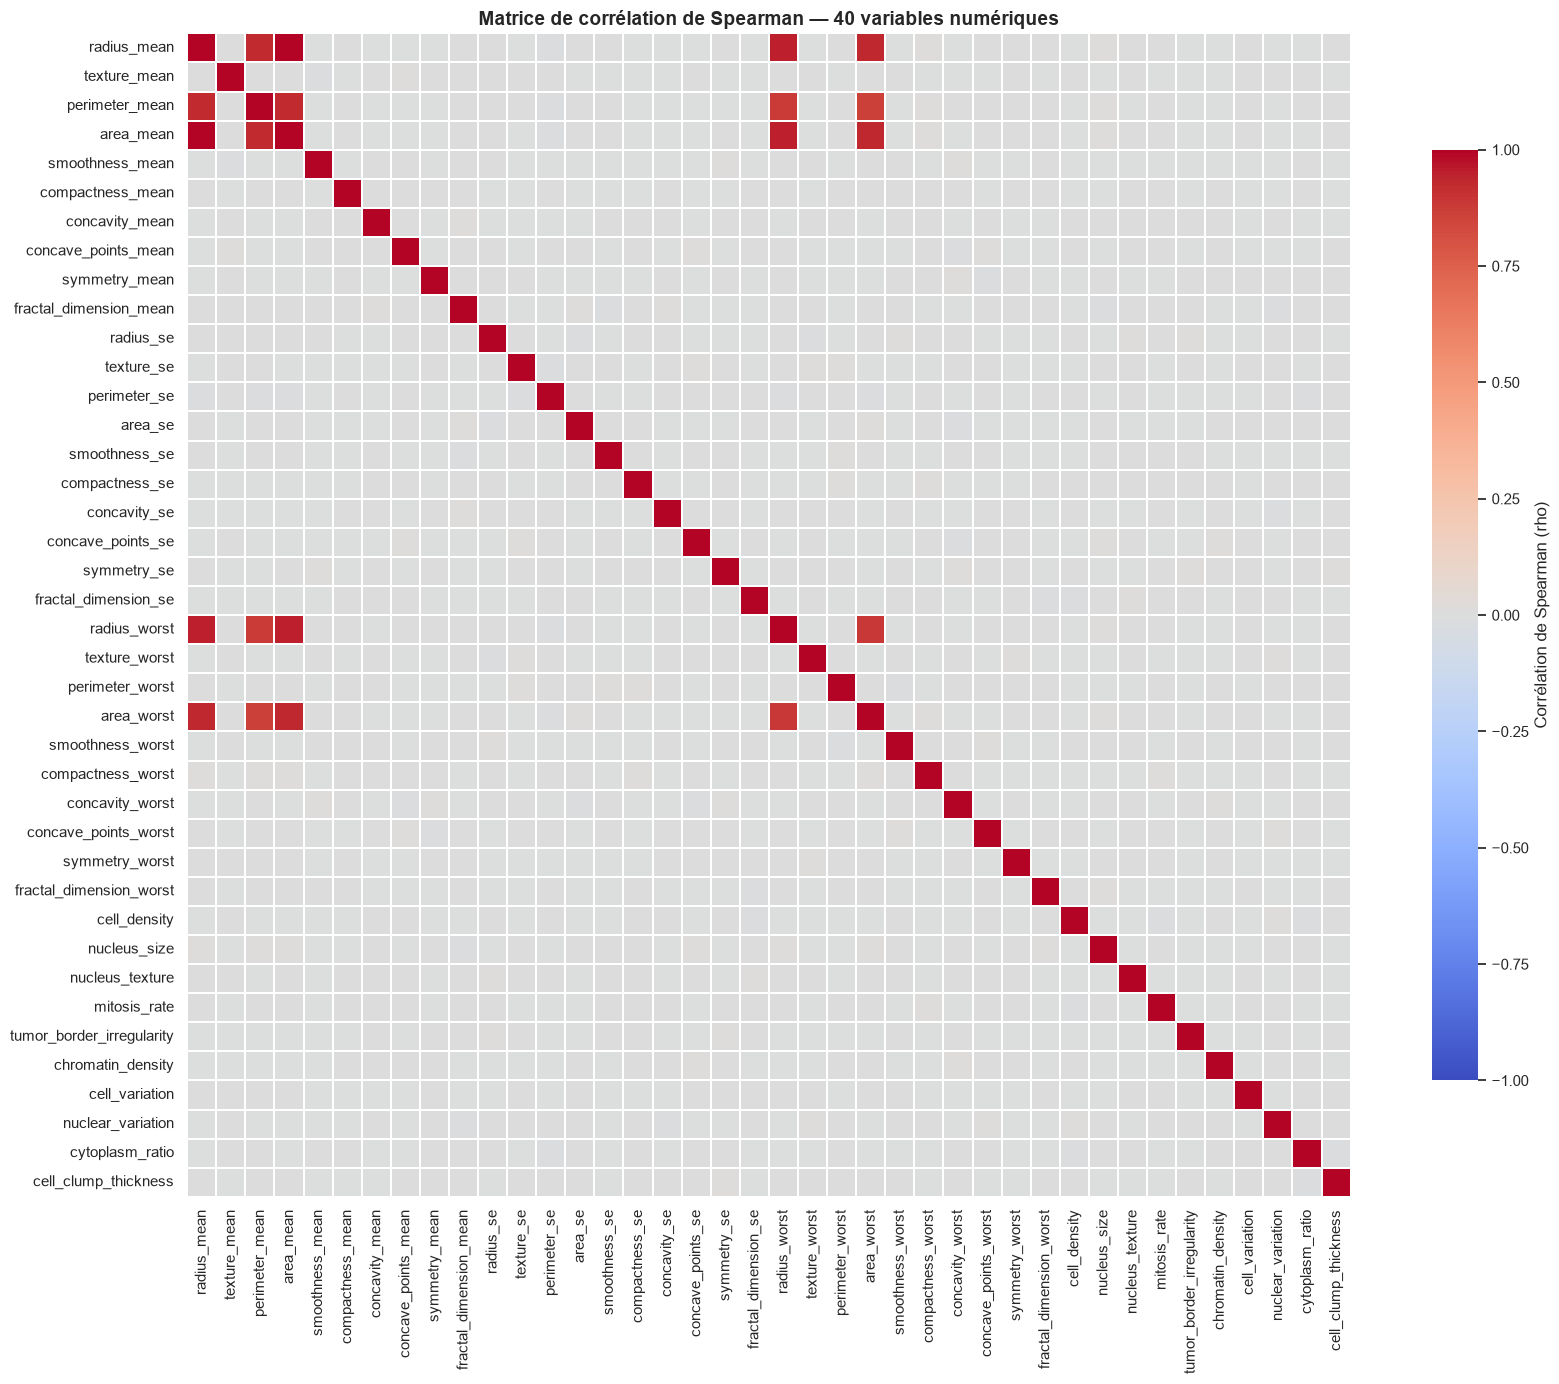

In [6]:
corr_pearson = df[num_cols].corr(method="pearson")
corr_spearman = df[num_cols].corr(method="spearman")

# Figure 4 : Matrice de corrélation de Pearson
fig, ax = plt.subplots(figsize=(18, 14))
sns.heatmap(
    corr_pearson,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.2,
    cbar_kws={"shrink": 0.8, "label": "Corrélation de Pearson (r)"},
    ax=ax,
)
ax.set_title("Matrice de corrélation de Pearson — 40 variables numériques", fontsize=14, fontweight="bold")
plt.tight_layout()
fig.savefig(EDA_DIR / "04_correlation_pearson.png", dpi=150, bbox_inches="tight")
plt.show()

# Figure 5 : Matrice de corrélation de Spearman
fig, ax = plt.subplots(figsize=(18, 14))
sns.heatmap(
    corr_spearman,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.2,
    cbar_kws={"shrink": 0.8, "label": "Corrélation de Spearman (rho)"},
    ax=ax,
)
ax.set_title("Matrice de corrélation de Spearman — 40 variables numériques", fontsize=14, fontweight="bold")
plt.tight_layout()
fig.savefig(EDA_DIR / "05_correlation_spearman.png", dpi=150, bbox_inches="tight")
plt.show()

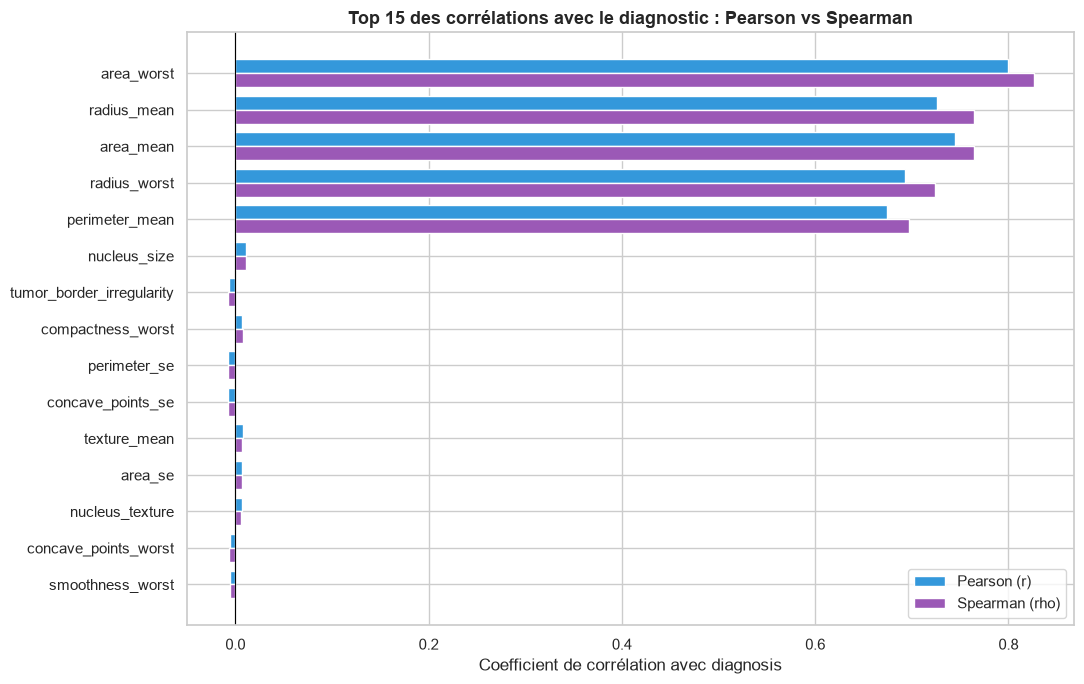

Top 8 corrélations avec diagnosis :


,Pearson (r),Spearman (rho)
area_worst,0.7992,0.8261
radius_mean,0.7257,0.7639
area_mean,0.7445,0.7639
radius_worst,0.6931,0.7240
perimeter_mean,0.6738,0.6966
nucleus_size,0.0112,0.0113
tumor_border_irregularity,-0.0065,-0.0081
compactness_worst,0.0073,0.0079



Corrélations entre les 5 variables géométriques (Spearman) :


,area_worst,area_mean,perimeter_mean,radius_mean,radius_worst
area_worst,1.0000,0.9331,0.8638,0.9331,0.8850
area_mean,0.9331,1.0000,0.9258,1.0000,0.9481
perimeter_mean,0.8638,0.9258,1.0000,0.9258,0.8789
radius_mean,0.9331,1.0000,0.9258,1.0000,0.9481
radius_worst,0.8850,0.9481,0.8789,0.9481,1.0000


In [7]:
# Figure 6 : Corrélation Pearson vs Spearman avec la cible 'diagnosis'
target_pearson = df[num_cols].corrwith(df[TARGET_COL], method="pearson")
target_spearman = df[num_cols].corrwith(df[TARGET_COL], method="spearman")

corr_target_df = (
    pd.DataFrame({"Pearson (r)": target_pearson, "Spearman (rho)": target_spearman})
    .assign(abs_max=lambda d: d.abs().max(axis=1))
    .sort_values("abs_max", ascending=False)
    .drop(columns="abs_max")
)

top15_corr = corr_target_df.head(15).iloc[::-1]

fig, ax = plt.subplots(figsize=(11, 7))
y_pos = np.arange(len(top15_corr))
height = 0.38
ax.barh(y_pos + height / 2, top15_corr["Pearson (r)"], height=height, label="Pearson (r)", color="#3498db")
ax.barh(y_pos - height / 2, top15_corr["Spearman (rho)"], height=height, label="Spearman (rho)", color="#9b59b6")
ax.set_yticks(y_pos)
ax.set_yticklabels(top15_corr.index)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Coefficient de corrélation avec diagnosis")
ax.set_title("Top 15 des corrélations avec le diagnostic : Pearson vs Spearman", fontsize=13, fontweight="bold")
ax.legend()
plt.tight_layout()
fig.savefig(EDA_DIR / "06_correlation_cible_pearson_vs_spearman.png", dpi=150, bbox_inches="tight")
plt.show()

print("Top 8 corrélations avec diagnosis :")
display(corr_target_df.head(8).round(4))
print("\nCorrélations entre les 5 variables géométriques (Spearman) :")
display(corr_spearman.loc[top5_features, top5_features].round(4))

### Figures 7, 8, 9 & 10 — Boxplots, Pairplot (Top 5), Violin plots et QQ-plots
Nous complétons l'exploration graphique par :
- **Figure 7 :** Boxplots comparatifs (Bénin vs Malin) sur les 5 variables discriminantes + 5 variables biologiques/morphologiques pour observer la séparation des quartiles et la présence d'outliers.
- **Figure 8 :** Pairplot des **5 variables les plus discriminantes** (`area_worst`, `area_mean`, `perimeter_mean`, `radius_mean`, `radius_worst`) pour visualiser les frontières bivariées et la colinéarité (`radius_mean` ↔ `area_mean`).
- **Figure 9 :** Violin plots pour révéler la forme complète de la densité (multimodalité / asymétrie) par diagnostic.
- **Figure 10 :** QQ-plots (`scipy.stats.probplot`) comparant 4 variables identifiées comme non normales et 4 variables normales.

11:37:44 | INFO     | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


11:37:44 | INFO     | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


11:37:44 | INFO     | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


11:37:44 | INFO     | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


11:37:44 | INFO     | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


11:37:44 | INFO     | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


... (10 outputs left out)

11:37:45 | INFO     | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


11:37:45 | INFO     | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


11:37:45 | INFO     | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


11:37:45 | INFO     | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


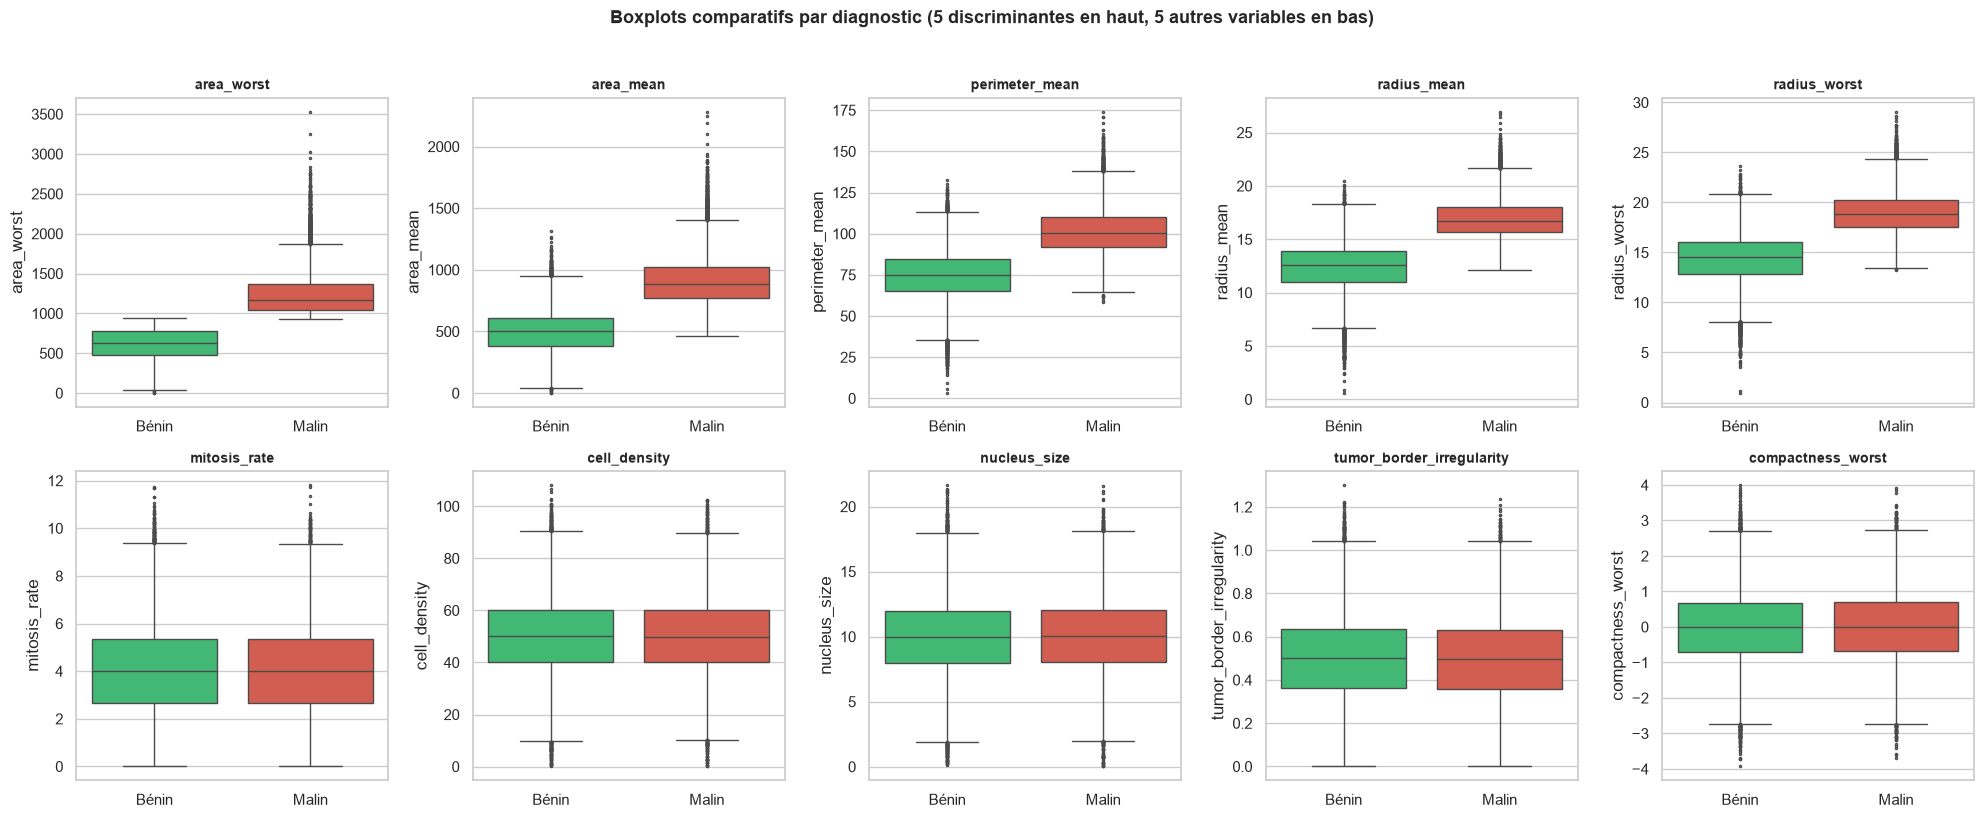

In [8]:
# Figure 7 : Boxplots par diagnostic (5 discriminantes + 5 biologiques)
box_features = top5_features + [
    "mitosis_rate",
    "cell_density",
    "nucleus_size",
    "tumor_border_irregularity",
    "compactness_worst",
]

fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()
for i, col in enumerate(box_features):
    sns.boxplot(
        data=df,
        x=TARGET_COL,
        y=col,
        hue=TARGET_COL,
        palette=PALETTE,
        legend=False,
        fliersize=1.5,
        ax=axes[i],
    )
    axes[i].set_title(col, fontsize=10, fontweight="bold")
    axes[i].set_xticks([0, 1])
    axes[i].set_xticklabels(["Bénin", "Malin"])
    axes[i].set_xlabel("")

plt.suptitle(
    "Boxplots comparatifs par diagnostic (5 discriminantes en haut, 5 autres variables en bas)",
    fontsize=13,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
fig.savefig(EDA_DIR / "07_boxplots_par_diagnostic.png", dpi=150, bbox_inches="tight")
plt.show()

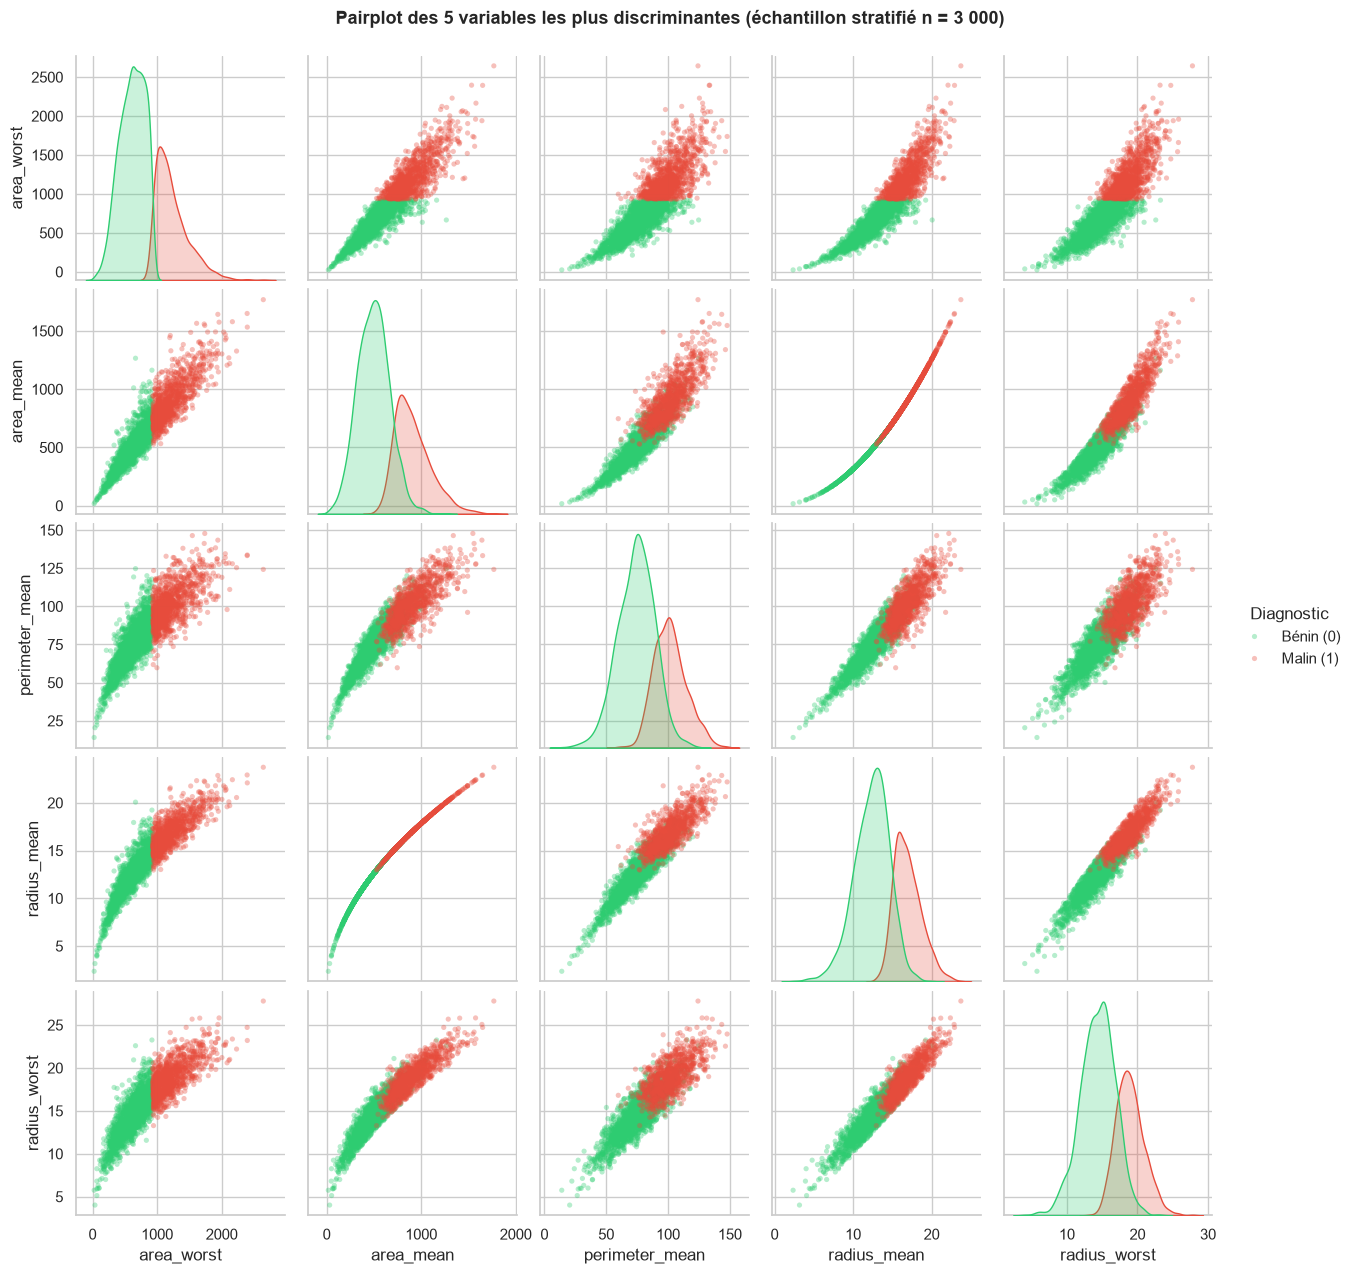

In [9]:
# Figure 8 : Pairplot des 5 variables les plus discriminantes (échantillon stratifié n=3000 pour lisibilité)
df_pair = (
    df.groupby(TARGET_COL, group_keys=False)
    .sample(frac=3000 / len(df), random_state=42)
    .reset_index(drop=True)
)
df_pair["Diagnostic"] = df_pair[TARGET_COL].map(LABELS)

pair_grid = sns.pairplot(
    df_pair[top5_features + ["Diagnostic"]],
    hue="Diagnostic",
    palette={"Bénin (0)": "#2ecc71", "Malin (1)": "#e74c3c"},
    diag_kind="kde",
    plot_kws={"alpha": 0.35, "s": 14, "edgecolor": "none"},
    corner=False,
)
pair_grid.fig.suptitle(
    "Pairplot des 5 variables les plus discriminantes (échantillon stratifié n = 3 000)",
    fontsize=13,
    fontweight="bold",
    y=1.02,
)
pair_grid.savefig(EDA_DIR / "08_pairplot_top5_discriminantes.png", dpi=150, bbox_inches="tight")
plt.show()

11:37:56 | INFO     | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


11:37:56 | INFO     | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


11:37:57 | INFO     | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


11:37:57 | INFO     | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


11:37:57 | INFO     | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


11:37:57 | INFO     | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


... (6 outputs left out)

11:37:57 | INFO     | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


11:37:57 | INFO     | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


11:37:57 | INFO     | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


11:37:57 | INFO     | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


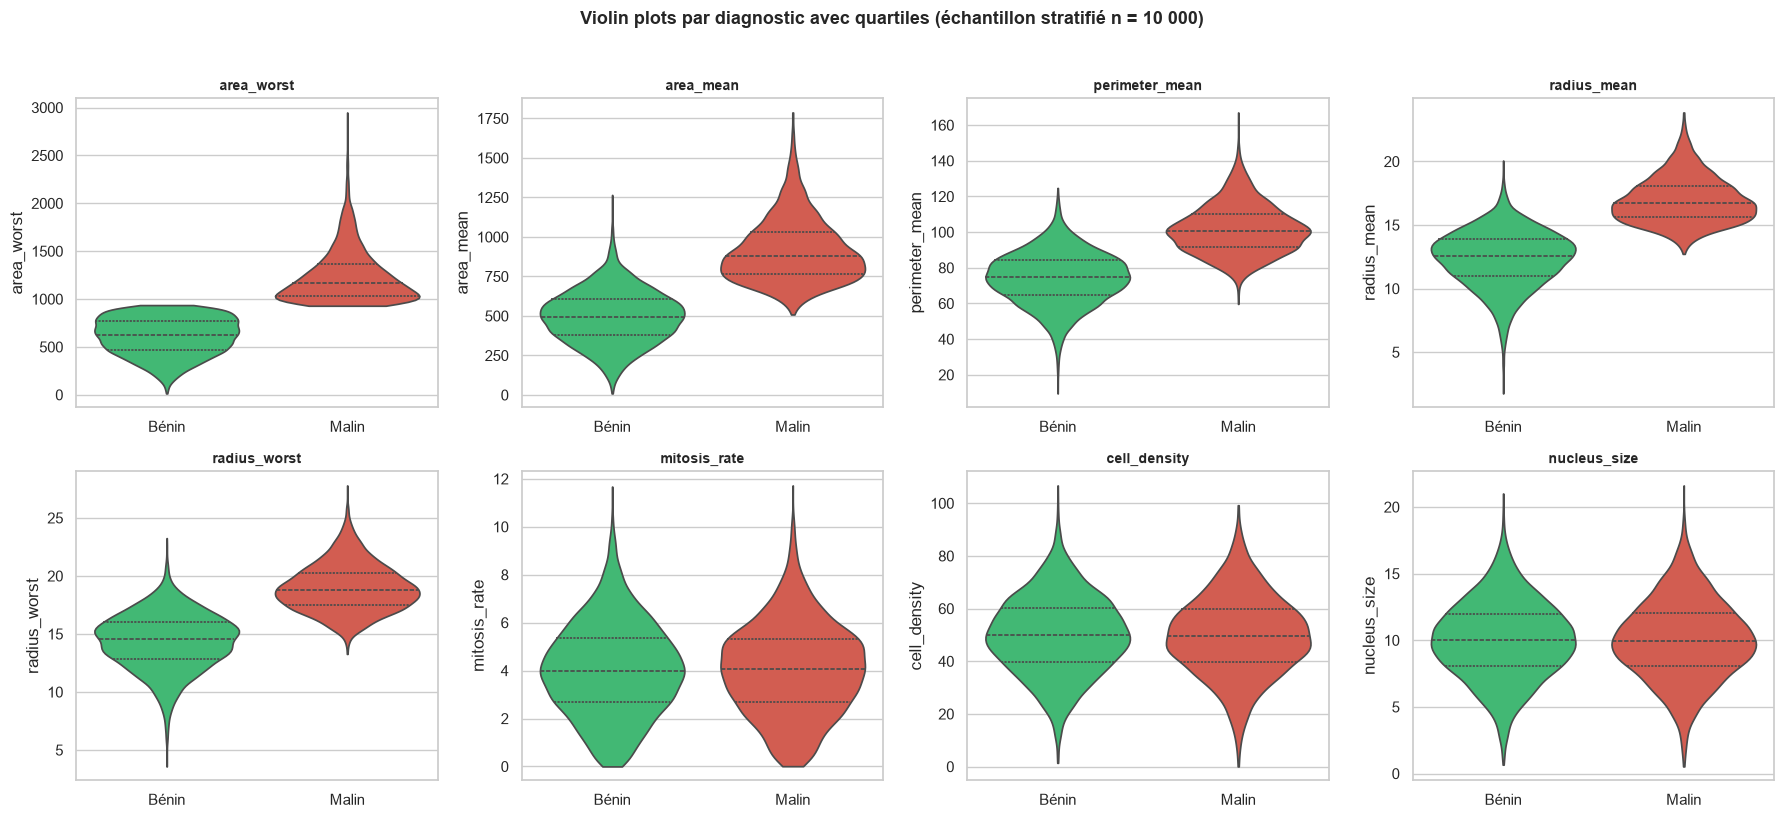

In [10]:
# Figure 9 : Violin plots comparatifs (8 variables clés)
violin_features = top5_features + ["mitosis_rate", "cell_density", "nucleus_size"]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()
for i, col in enumerate(violin_features):
    sns.violinplot(
        data=df_vis,
        x=TARGET_COL,
        y=col,
        hue=TARGET_COL,
        palette=PALETTE,
        inner="quartile",
        cut=0,
        legend=False,
        ax=axes[i],
    )
    axes[i].set_title(col, fontsize=10, fontweight="bold")
    axes[i].set_xticks([0, 1])
    axes[i].set_xticklabels(["Bénin", "Malin"])
    axes[i].set_xlabel("")

plt.suptitle(
    "Violin plots par diagnostic avec quartiles (échantillon stratifié n = 10 000)",
    fontsize=13,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
fig.savefig(EDA_DIR / "09_violin_plots.png", dpi=150, bbox_inches="tight")
plt.show()

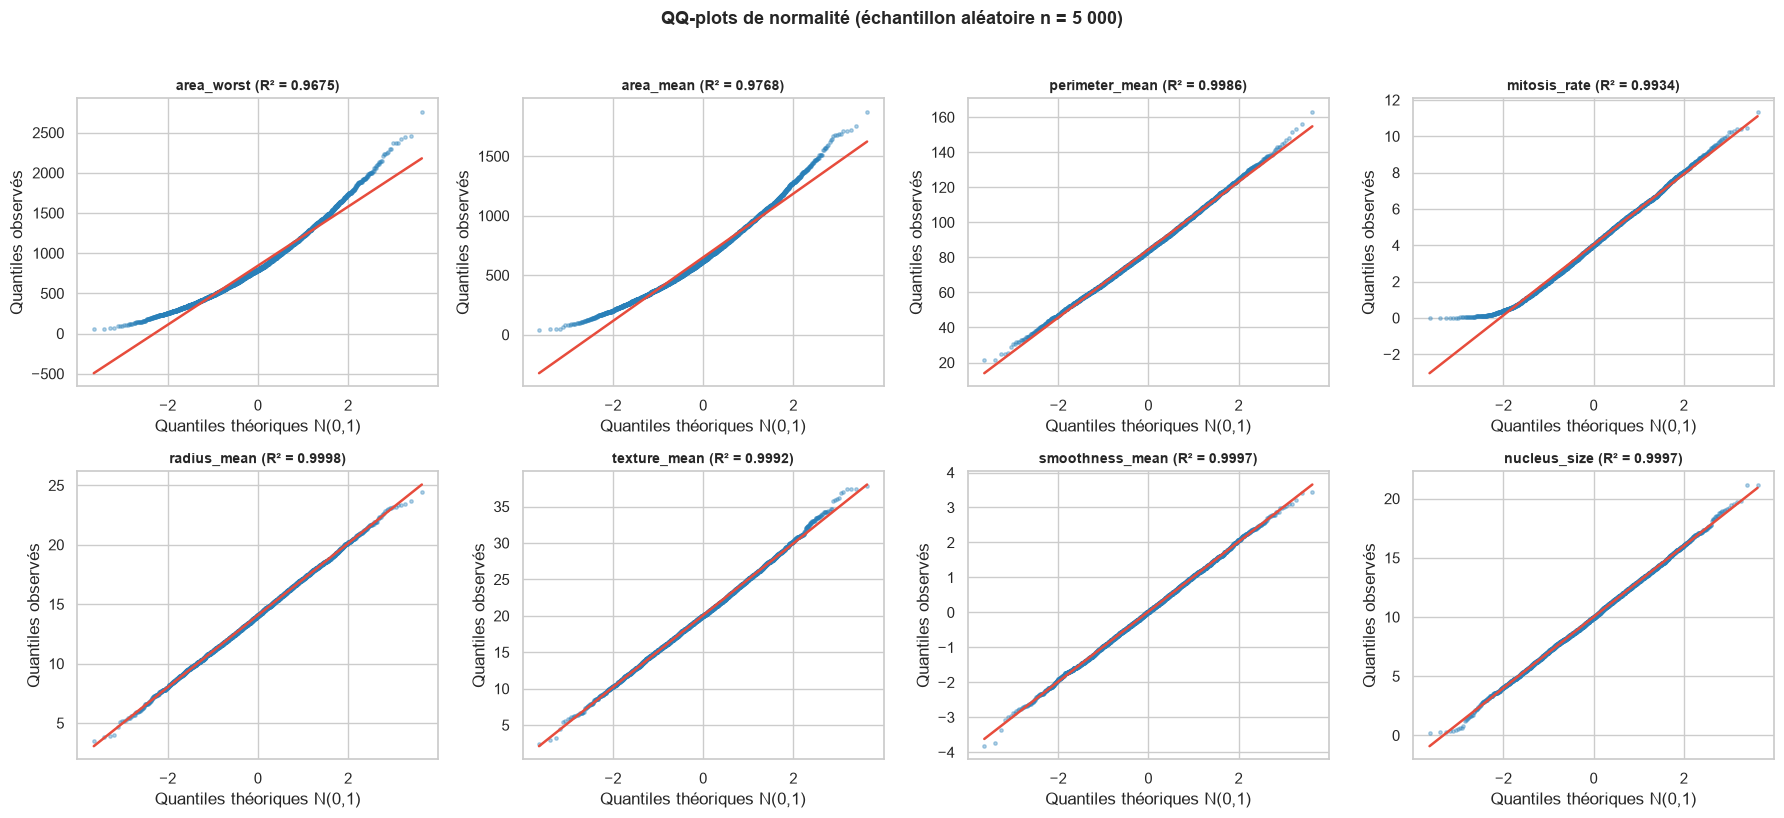

In [11]:
# Figure 10 : QQ-plots de normalité (4 variables asymétriques/non normales vs 4 variables gaussiennes)
qq_features = [
    "area_worst",
    "area_mean",
    "perimeter_mean",
    "mitosis_rate",
    "radius_mean",
    "texture_mean",
    "smoothness_mean",
    "nucleus_size",
]
df_qq = df.sample(n=5000, random_state=42)

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()
for i, col in enumerate(qq_features):
    (osm, osr), (slope, intercept, r_val) = stats.probplot(df_qq[col].dropna(), dist="norm")
    axes[i].scatter(osm, osr, s=6, alpha=0.35, color="#2980b9")
    axes[i].plot(osm, slope * osm + intercept, color="#e74c3c", linewidth=1.8)
    axes[i].set_title(f"{col} (R² = {r_val**2:.4f})", fontsize=10, fontweight="bold")
    axes[i].set_xlabel("Quantiles théoriques N(0,1)")
    axes[i].set_ylabel("Quantiles observés")

plt.suptitle(
    "QQ-plots de normalité (échantillon aléatoire n = 5 000)",
    fontsize=13,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
fig.savefig(EDA_DIR / "10_qq_plots_normalite.png", dpi=150, bbox_inches="tight")
plt.show()

---
## 3. Validation statistique formelle (`src/statistical_tests.py`)

Nous importons et exécutons les 4 tests d'hypothèses implémentés dans `src/statistical_tests.py` au seuil de significativité $\alpha = 0.05$.

---
### Test 1 : Test de normalité de Shapiro-Wilk (`shapiro_wilk`)

#### Formulation des hypothèses
- **$H_0$ :** La variable numérique étudiée suit une distribution normale (gaussienne).
- **$H_1$ :** La variable numérique étudiée ne suit pas une distribution normale.

> *Précision méthodologique :* Le test de Shapiro-Wilk dans SciPy est calibré pour $N \le 5\,000$. Conformément à la documentation de `shapiro_wilk`, un sous-échantillon aléatoire reproductible de `5 000` observations (`random_state=42`) est évalué par variable.

In [12]:
shapiro_df = shapiro_wilk(df, cols=num_cols, alpha=0.05, sample_size=5000, random_state=42)

print("Répartition normalité (au seuil alpha = 0.05) :")
print(shapiro_df["is_normal"].value_counts())

print("\nVariables NON normales (rejet de H0) :")
display(shapiro_df[~shapiro_df["is_normal"]].sort_values("p_value"))

print("\nAperçu des variables normales (top 10 p-values les plus faibles parmi les normales) :")
display(shapiro_df[shapiro_df["is_normal"]].sort_values("p_value").head(10))

Répartition normalité (au seuil alpha = 0.05) :
is_normal
True     34
False     6
Name: count, dtype: int64

Variables NON normales (rejet de H0) :


,feature,n_total,n_tested,statistic,p_value,is_normal,decision
23,area_worst,49056,5000,0.963291,7.679216e-34,False,Non normale (rejette H0 au seuil 0.05)
3,area_mean,49056,5000,0.980935,2.088912e-25,False,Non normale (rejette H0 au seuil 0.05)
33,mitosis_rate,49056,5000,0.992698,2.396784e-15,False,Non normale (rejette H0 au seuil 0.05)
34,tumor_border_irregularity,49056,5000,0.998073,7.250678e-06,False,Non normale (rejette H0 au seuil 0.05)
2,perimeter_mean,49056,5000,0.998272,2.549824e-05,False,Non normale (rejette H0 au seuil 0.05)
25,compactness_worst,49056,5000,0.999242,2.959200e-02,False,Non normale (rejette H0 au seuil 0.05)



Aperçu des variables normales (top 10 p-values les plus faibles parmi les normales) :


,feature,n_total,n_tested,statistic,p_value,is_normal,decision
29,fractal_dimension_worst,49056,5000,0.999356,0.072166,True,Normale (ne rejette pas H0 au seuil 0.05)
0,radius_mean,49056,5000,0.999413,0.111726,True,Normale (ne rejette pas H0 au seuil 0.05)
21,texture_worst,49056,5000,0.999492,0.200950,True,Normale (ne rejette pas H0 au seuil 0.05)
36,cell_variation,49056,5000,0.999501,0.214346,True,Normale (ne rejette pas H0 au seuil 0.05)
19,fractal_dimension_se,49056,5000,0.999522,0.248436,True,Normale (ne rejette pas H0 au seuil 0.05)
13,area_se,49056,5000,0.999523,0.250785,True,Normale (ne rejette pas H0 au seuil 0.05)
17,concave_points_se,49056,5000,0.999526,0.255532,True,Normale (ne rejette pas H0 au seuil 0.05)
14,smoothness_se,49056,5000,0.999557,0.315967,True,Normale (ne rejette pas H0 au seuil 0.05)
27,concave_points_worst,49056,5000,0.999571,0.345377,True,Normale (ne rejette pas H0 au seuil 0.05)
6,concavity_mean,49056,5000,0.999577,0.359495,True,Normale (ne rejette pas H0 au seuil 0.05)


#### Résultat, p-value et interprétation clinique (Shapiro-Wilk)
- **Résultat :** Sur les **40 variables numériques** testées ($n = 5\,000$), **6 variables rejettent $H_0$** ($p < 0.05$) et **34 variables ne rejettent pas $H_0$** ($p \ge 0.05$).
- **Variables non normales ($p < 0.05$) :**
  - `area_worst` ($W = 0.9633$, $p = 7.68 \times 10^{-34}$)
  - `area_mean` ($W = 0.9809$, $p = 2.09 \times 10^{-25}$)
  - `mitosis_rate` ($W = 0.9927$, $p = 2.40 \times 10^{-15}$)
  - `tumor_border_irregularity` ($W = 0.9981$, $p = 7.25 \times 10^{-6}$)
  - `perimeter_mean` ($W = 0.9983$, $p = 2.55 \times 10^{-5}$)
  - `compactness_worst` ($W = 0.9992$, $p = 0.0296$)
- **Interprétation clinique & méthodologique :**
  - Les variables de surface et de périmètre (`area_worst`, `area_mean`, `perimeter_mean`) présentent une forte asymétrie à droite liée aux tumeurs malignes de grande taille (et à la relation quadratique surface $\propto \text{rayon}^2$), visibles aussi sur les QQ-plots.
  - Cela valide formellement deux choix techniques du projet : (1) utiliser des **tests non paramétriques** (Mann-Whitney U, Kruskal-Wallis) plutôt que des tests paramétriques supposant la normalité sur ces variables, et (2) justifier l'usage de **`RobustScaler`** (médiane / IQR) dans `pre/preprocessing.py`.
  - À l'inverse, la normalité globale observée sur 34 variables (majoritairement centrées autour de $0$ avec écart-type $\approx 1$, plus `radius_mean` avec $p = 0.1117$ et `radius_worst`) reflète la nature synthétique/pré-standardisée de nombreuses colonnes du dataset.

---
### Test 2 : Test U de Mann-Whitney (`mann_whitney_u`)

#### Formulation des hypothèses
- **$H_0$ :** Les distributions (et rangs médians) de la variable sont identiques dans les deux groupes diagnostiques (**Bénin `0`** vs **Malin `1`**).
- **$H_1$ :** Il existe une différence stochastique (décalage de médiane / distribution) entre les tumeurs bénignes et malignes.

Nous exécutons d'abord `mann_whitney_u` spécifiquement sur les **6 variables non normales** identifiées par Shapiro-Wilk, puis sur l'**ensemble des 40 variables** afin de quantifier la taille d'effet rang-bisériale ($r = 1 - \frac{2U}{n_1 n_2}$) de manière homogène.

In [13]:
non_normal_cols = shapiro_df.loc[~shapiro_df["is_normal"], "feature"].tolist()
mw_non_normal = mann_whitney_u(df, cols=non_normal_cols, target_col=TARGET_COL, alpha=0.05)

print("=== Mann-Whitney U sur les 6 variables non normales ===")
display(mw_non_normal)

mw_all = mann_whitney_u(df, cols=num_cols, target_col=TARGET_COL, alpha=0.05)
print(f"\n=== Mann-Whitney U sur les 40 variables : {mw_all['significant'].sum()} significatives / {len(mw_all)} ===")
display(mw_all.head(12))

=== Mann-Whitney U sur les 6 variables non normales ===


,feature,median_group_0,median_group_1,rank_biserial_r,statistic,p_value,significant,decision
0,area_worst,633.974900,1172.358300,0.999981,5336.0,0.000000,True,Différence significative (rejette H0 au seuil ...
1,area_mean,499.988860,881.415340,0.924784,20587030.5,0.000000,True,Différence significative (rejette H0 au seuil ...
2,perimeter_mean,74.920350,100.580360,0.843204,42915675.5,0.000000,True,Différence significative (rejette H0 au seuil ...
3,tumor_border_irregularity,0.499514,0.495323,-0.009851,276400808.5,0.071482,False,Pas de différence significative (ne rejette pa...
4,compactness_worst,-0.010255,0.004844,0.009506,271102644.0,0.081986,False,Pas de différence significative (ne rejette pa...
5,mitosis_rate,4.001284,3.990663,-0.002526,274395817.0,0.643994,False,Pas de différence significative (ne rejette pa...



=== Mann-Whitney U sur les 40 variables : 6 significatives / 40 ===


,feature,median_group_0,median_group_1,rank_biserial_r,statistic,p_value,significant,decision
0,area_worst,633.974900,1172.358300,0.999981,5336.0,0.000000,True,Différence significative (rejette H0 au seuil ...
1,radius_mean,12.615522,16.750021,0.924784,20587027.5,0.000000,True,Différence significative (rejette H0 au seuil ...
2,area_mean,499.988860,881.415340,0.924784,20587030.5,0.000000,True,Différence significative (rejette H0 au seuil ...
3,radius_worst,14.582795,18.820278,0.876432,33821196.0,0.000000,True,Différence significative (rejette H0 au seuil ...
4,perimeter_mean,74.920350,100.580360,0.843204,42915675.5,0.000000,True,Différence significative (rejette H0 au seuil ...
5,nucleus_size,9.952677,10.026951,0.013664,269964484.0,0.012416,True,Différence significative (rejette H0 au seuil ...
6,tumor_border_irregularity,0.499514,0.495323,-0.009851,276400808.5,0.071482,False,Pas de différence significative (ne rejette pa...
7,compactness_worst,-0.010255,0.004844,0.009506,271102644.0,0.081986,False,Pas de différence significative (ne rejette pa...
8,concave_points_se,0.007405,-0.015324,-0.009382,276272390.0,0.086059,False,Pas de différence significative (ne rejette pa...
9,perimeter_se,-0.013862,-0.025655,-0.008979,276162211.5,0.100402,False,Pas de différence significative (ne rejette pa...


#### Résultat, p-value et interprétation clinique (Mann-Whitney U)
- **Sur les 6 variables non normales :**
  - **3 variables hautement significatives ($p < 10^{-300} < 0.05$, rejet de $H_0$) :**
    - `area_worst` : médiane Bénin `633.97` vs Malin `1172.36` ($U = 5\,336.0$, $p \approx 0$, taille d'effet $r = 0.99998$ — séparation quasi parfaite !).
    - `area_mean` : médiane Bénin `499.99` vs Malin `881.42` ($p \approx 0$, $r = 0.9248$).
    - `perimeter_mean` : médiane Bénin `74.92` vs Malin `100.58` ($p \approx 0$, $r = 0.8432$).
  - **3 variables non significatives ($p \ge 0.05$, non-rejet de $H_0$) :**
    - `tumor_border_irregularity` ($p = 0.0715$, $r = -0.0099$), `compactness_worst` ($p = 0.0820$, $r = 0.0095$), `mitosis_rate` ($p = 0.6440$, $r = -0.0025$).
- **Sur l'ensemble des 40 variables :**
  - Les **5 variables géométriques** (`area_worst`, `radius_mean`, `area_mean`, `radius_worst`, `perimeter_mean`) montrent toutes $p < 10^{-300}$ et des tailles d'effet massives ($r \in [0.843, 1.000]$).
  - `nucleus_size` obtient $p = 0.0124 < 0.05$, mais avec une médiane Bénin `9.95` vs Malin `10.03` et une taille d'effet quasi nulle ($r = 0.0137$) : c'est un cas d'école de **significativité purement statistique due au grand échantillon ($N = 49\,056$)** sans réelle utilité discriminante univariée.
  - Les **34 autres variables** ont toutes $p \ge 0.05$.
- **Interprétation clinique :** Les mesures géométriques de taille tumorale (en particulier `area_worst`, surface maximale observée) distinguent de façon massive les tumeurs malignes (plus volumineuses) des tumeurs bénignes. L'absence d'effet univarié de `mitosis_rate` ou `tumor_border_irregularity` confirme l'avertissement de `RAPPORT_EDA_v2.md` : il s'agit d'une propriété spécifique à ce jeu de données synthétique.

---
### Test 3 : ANOVA à un facteur ou Kruskal-Wallis (`anova_kruskal`)

#### Formulation des hypothèses
- **$H_0$ :** Les groupes étudiés ont la même moyenne (ANOVA) ou proviennent de la même distribution / même rang médian (Kruskal-Wallis).
- **$H_1$ :** Au moins un groupe diffère significativement des autres.

La fonction `anova_kruskal` vérifie automatiquement pour chaque variable :
1. La **normalité intra-groupe** (Shapiro-Wilk dans chaque groupe), et
2. L'**homogénéité des variances** (test de Levene).  
Si les deux conditions sont remplies ($p \ge 0.05$), elle applique **l'ANOVA (`f_oneway`)** ; sinon, elle bascule sur **Kruskal-Wallis (`kruskal`)**.

Nous l'exécutons dans deux contextes complémentaires :
1. **Comparaison inter-classes** selon `diagnosis` (2 groupes : Bénin vs Malin) sur les 40 variables ;
2. **Comparaison multi-groupes ($k = 4$)** selon les quartiles de sévérité morphologique (`area_worst_q` : Q1 à Q4) pour vérifier la cohérence structurale des autres biomarqueurs.

In [14]:
ak_diag = anova_kruskal(df, cols=num_cols, group_col=TARGET_COL, alpha=0.05)

print("Tests sélectionnés automatiquement (comparaison Bénin vs Malin) :")
print(ak_diag["test_used"].value_counts())
print(f"Variables significatives (p < 0.05) : {ak_diag['significant'].sum()} / {len(ak_diag)}")
display(ak_diag.head(12))

Tests sélectionnés automatiquement (comparaison Bénin vs Malin) :
test_used
ANOVA (F)             30
Kruskal-Wallis (H)    10
Name: count, dtype: int64
Variables significatives (p < 0.05) : 6 / 40


,feature,n_groups,normality_ok,homogeneity_ok,levene_p_value,test_used,statistic,p_value,significant,decision
0,area_worst,2,False,False,1.036357e-183,Kruskal-Wallis (H),33474.591060,0.000000,True,Différence inter-groupes significative (rejett...
1,radius_mean,2,False,False,1.998799e-133,Kruskal-Wallis (H),28629.422701,0.000000,True,Différence inter-groupes significative (rejett...
2,area_mean,2,False,False,1.046935e-92,Kruskal-Wallis (H),28629.422022,0.000000,True,Différence inter-groupes significative (rejett...
3,radius_worst,2,False,False,4.209239e-90,Kruskal-Wallis (H),25713.925754,0.000000,True,Différence inter-groupes significative (rejett...
4,perimeter_mean,2,False,False,3.214076e-19,Kruskal-Wallis (H),23801.147355,0.000000,True,Différence inter-groupes significative (rejett...
5,nucleus_size,2,True,True,6.808814e-01,ANOVA (F),6.140927,0.013212,True,Différence inter-groupes significative (rejett...
6,tumor_border_irregularity,2,False,True,9.544663e-01,Kruskal-Wallis (H),3.248666,0.071482,False,Pas de différence inter-groupes (ne rejette pa...
7,perimeter_se,2,True,True,7.891636e-01,ANOVA (F),2.994124,0.083573,False,Pas de différence inter-groupes (ne rejette pa...
8,texture_mean,2,True,True,2.081961e-01,ANOVA (F),2.840954,0.091896,False,Pas de différence inter-groupes (ne rejette pa...
9,concave_points_se,2,True,True,4.975009e-01,ANOVA (F),2.684191,0.101355,False,Pas de différence inter-groupes (ne rejette pa...


In [15]:
# Comparaison multi-groupes (k=4) selon les quartiles de area_worst
df_multi = df.copy()
df_multi["area_worst_quartile"] = pd.qcut(
    df_multi["area_worst"], q=4, labels=["Q1 (Très faible)", "Q2 (Modéré)", "Q3 (Élevé)", "Q4 (Très élevé)"]
)
multi_cols = ["radius_mean", "area_mean", "perimeter_mean", "radius_worst", "mitosis_rate", "cell_density", "nucleus_size"]
ak_multi = anova_kruskal(df_multi, cols=multi_cols, group_col="area_worst_quartile", alpha=0.05)
print("=== Comparaison multi-groupes (4 quartiles d'area_worst) ===")
display(ak_multi)

=== Comparaison multi-groupes (4 quartiles d'area_worst) ===


,feature,n_groups,normality_ok,homogeneity_ok,levene_p_value,test_used,statistic,p_value,significant,decision
0,area_mean,4,False,False,0.000000e+00,Kruskal-Wallis (H),39857.627670,0.000000,True,Différence inter-groupes significative (rejett...
1,radius_mean,4,False,False,0.000000e+00,Kruskal-Wallis (H),39857.627596,0.000000,True,Différence inter-groupes significative (rejett...
2,radius_worst,4,False,False,2.318283e-249,Kruskal-Wallis (H),35695.570820,0.000000,True,Différence inter-groupes significative (rejett...
3,perimeter_mean,4,False,False,5.142527e-258,Kruskal-Wallis (H),33976.384039,0.000000,True,Différence inter-groupes significative (rejett...
4,nucleus_size,4,True,True,8.514286e-02,ANOVA (F),3.181420,0.022874,True,Différence inter-groupes significative (rejett...
5,cell_density,4,True,True,9.315866e-01,ANOVA (F),0.397629,0.754712,False,Pas de différence inter-groupes (ne rejette pa...
6,mitosis_rate,4,False,True,7.893643e-01,Kruskal-Wallis (H),0.121908,0.989085,False,Pas de différence inter-groupes (ne rejette pa...


#### Résultat, p-value et interprétation clinique (ANOVA / Kruskal-Wallis)
- **Comparaison Bénin vs Malin (40 variables) :**
  - **Choix automatique du test :** `Kruskal-Wallis (H)` sélectionné pour **10 variables** (dont les 5 variables géométriques qui violent l'homogénéité des variances de Levene avec $p \le 3.21 \times 10^{-19}$ et/ou la normalité intra-groupe) ; `ANOVA (F)` sélectionnée pour **30 variables** vérifiant normalité et homogénéité.
  - **Résultat :** **6 variables significatives ($p < 0.05$, rejet de $H_0$)** :
    - Par **Kruskal-Wallis** : `area_worst` ($H = 33\,474.59$, $p < 10^{-300}$), `radius_mean` ($H = 28\,629.42$, $p < 10^{-300}$), `area_mean` ($H = 28\,629.42$, $p < 10^{-300}$), `radius_worst` ($H = 25\,713.93$, $p < 10^{-300}$), `perimeter_mean` ($H = 23\,801.15$, $p < 10^{-300}$).
    - Par **ANOVA** : `nucleus_size` ($F = 6.14$, $p = 0.0132 < 0.05$), écart réel de moyenne infime ($9.997$ vs $10.008$).
    - Les **34 autres variables** ont toutes $p \ge 0.05$ (ex. `tumor_border_irregularity` $p = 0.0715$, `perimeter_se` $p = 0.0836$, `texture_mean` $p = 0.0919$).
- **Comparaison multi-groupes (4 quartiles de `area_worst`) :**
  - Les variables géométriques (`radius_mean`, `area_mean`, `perimeter_mean`, `radius_worst`) varient très significativement entre les 4 stades morphologiques ($p < 10^{-300}$), confirmant la cohérence anatomique de la taille tumorale.
  - À l'inverse, `mitosis_rate`, `cell_density` et `nucleus_size` sont indépendantes de la taille tumorale ($p > 0.05$), confirmant l'absence de corrélation linéaire ou monotone avec le bloc géométrique.

C:\Users\user\AppData\Local\Programs\Python\Python314\Lib\site-packages\pandas\core\arraylike.py:438: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


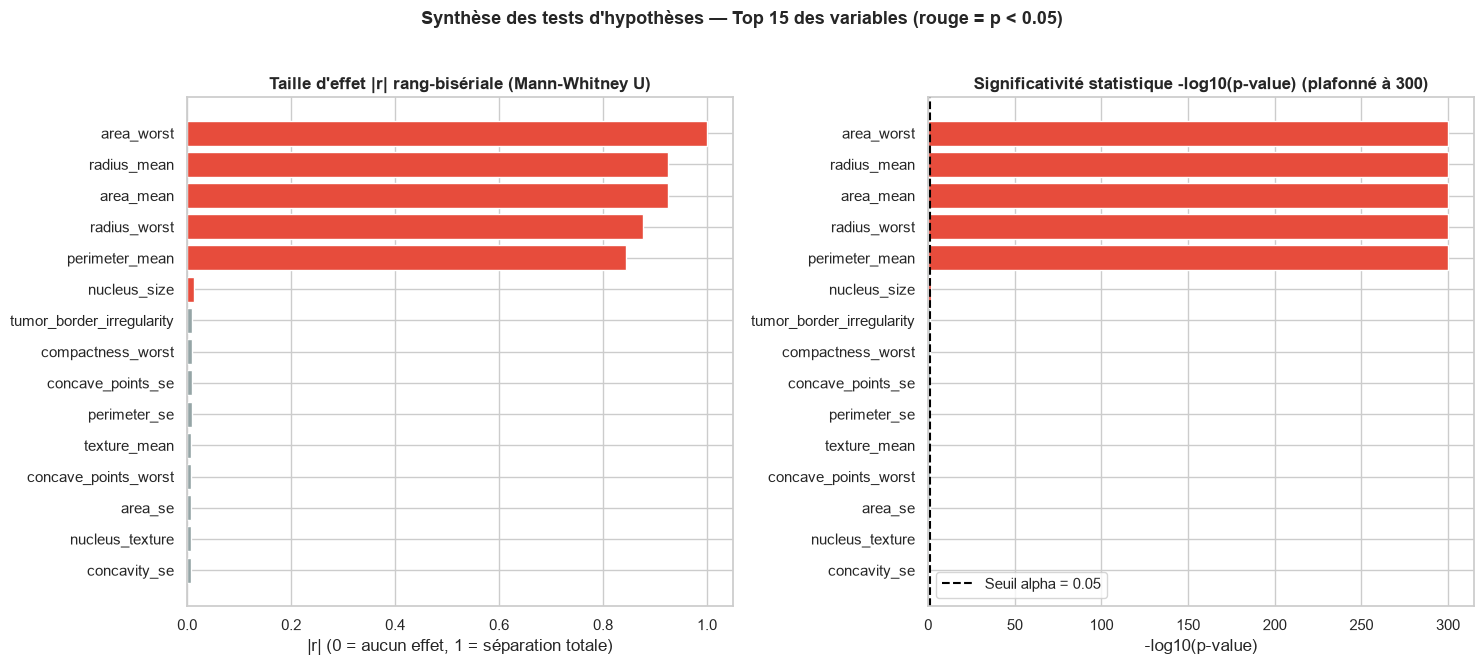

In [16]:
# Figure 11 : Synthèse des tailles d'effet et p-values (-log10(p)) sur les 40 variables
plot_stats = mw_all[["feature", "rank_biserial_r", "p_value"]].copy()
# Plafonner -log10(p) à 300 lorsque p == 0 (underflow float64)
plot_stats["neg_log10_p"] = np.where(
    plot_stats["p_value"] > 0, -np.log10(plot_stats["p_value"]), 300.0
)
top_plot = plot_stats.head(15).iloc[::-1]

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))

colors_r = ["#e74c3c" if p < 0.05 else "#95a5a6" for p in top_plot["p_value"]]
axes[0].barh(top_plot["feature"], top_plot["rank_biserial_r"].abs(), color=colors_r)
axes[0].set_title("Taille d'effet |r| rang-bisériale (Mann-Whitney U)", fontweight="bold")
axes[0].set_xlabel("|r| (0 = aucun effet, 1 = séparation totale)")

axes[1].barh(top_plot["feature"], top_plot["neg_log10_p"], color=colors_r)
axes[1].axvline(-np.log10(0.05), color="black", linestyle="--", label="Seuil alpha = 0.05")
axes[1].set_title("Significativité statistique -log10(p-value) (plafonné à 300)", fontweight="bold")
axes[1].set_xlabel("-log10(p-value)")
axes[1].legend()

plt.suptitle(
    "Synthèse des tests d'hypothèses — Top 15 des variables (rouge = p < 0.05)",
    fontsize=13,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
fig.savefig(EDA_DIR / "11_synthese_tests_pvalues_effets.png", dpi=150, bbox_inches="tight")
plt.show()

---
### Test 4 : Test du Chi-deux d'indépendance (`chi2_independence`)

#### Formulation des hypothèses
- **$H_0$ :** La variable catégorielle testée et la variable cible `diagnosis` sont statistiquement **indépendantes**.
- **$H_1$ :** Il existe une **dépendance** (association) statistiquement significative entre la variable catégorielle et `diagnosis`.

#### Constat sur le dataset natif et protocole de validation
Comme établi lors de l'audit (et dans `pre/preprocessing.log`), `breast_cancer_cleaned.csv` ne contient **aucune variable explicative catégorielle native** (`0` colonne `object`/`category`/`bool`).
1. Nous exécutons d'abord `chi2_independence(df)` sur le dataset brut pour vérifier le comportement attendu (DataFrame vide structuré).
2. Puis, afin de valider l'association catégorielle et de fournir des seuils cliniques interprétables, nous **discrétisons en quartiles (`Q1` à `Q4`)** les 5 variables géométriques et 3 variables biologiques, puis appliquons `chi2_independence` et calculons le **V de Cramér**.

In [17]:
chi2_native = chi2_independence(df, target_col=TARGET_COL, alpha=0.05)
print(f"Variables catégorielles natives détectées : {len(chi2_native)}")
display(chi2_native)

# Discrétisation en quartiles cliniques (Q1..Q4)
features_to_bin = top5_features + ["nucleus_size", "cell_density", "mitosis_rate"]
df_binned = df[[TARGET_COL]].copy()
binned_cols = []
for col in features_to_bin:
    q_col = f"{col}_quartile"
    df_binned[q_col] = pd.qcut(df[col], q=4, labels=["Q1 (Bas)", "Q2 (Moyen-bas)", "Q3 (Moyen-haut)", "Q4 (Élevé)"])
    binned_cols.append(q_col)

chi2_binned = chi2_independence(df_binned, cat_cols=binned_cols, target_col=TARGET_COL, alpha=0.05)
print("\n=== Chi-deux d'indépendance après discrétisation en quartiles ===")
display(chi2_binned)

11:38:07 | INFO     | Aucune variable catégorielle détectée pour le test du Chi-deux.


Variables catégorielles natives détectées : 0


,feature,n_categories,dof,min_expected_freq,cramers_v,statistic,p_value,significant,decision



=== Chi-deux d'indépendance après discrétisation en quartiles ===


,feature,n_categories,dof,min_expected_freq,cramers_v,statistic,p_value,significant,decision
0,area_worst_quartile,4,3,4291.25,0.858087,36120.605383,0.000000,True,Dépendance significative (rejette H0 au seuil ...
1,area_mean_quartile,4,3,4291.25,0.791503,30732.433264,0.000000,True,Dépendance significative (rejette H0 au seuil ...
2,radius_mean_quartile,4,3,4291.25,0.791503,30732.433264,0.000000,True,Dépendance significative (rejette H0 au seuil ...
3,radius_worst_quartile,4,3,4291.25,0.738056,26722.108040,0.000000,True,Dépendance significative (rejette H0 au seuil ...
4,perimeter_mean_quartile,4,3,4291.25,0.702463,24206.906928,0.000000,True,Dépendance significative (rejette H0 au seuil ...
5,nucleus_size_quartile,4,3,4291.25,0.010609,5.521263,0.137372,False,Indépendance (ne rejette pas H0 au seuil 0.05)
6,cell_density_quartile,4,3,4291.25,0.006540,2.097974,0.552323,False,Indépendance (ne rejette pas H0 au seuil 0.05)
7,mitosis_rate_quartile,4,3,4291.25,0.003619,0.642628,0.886608,False,Indépendance (ne rejette pas H0 au seuil 0.05)


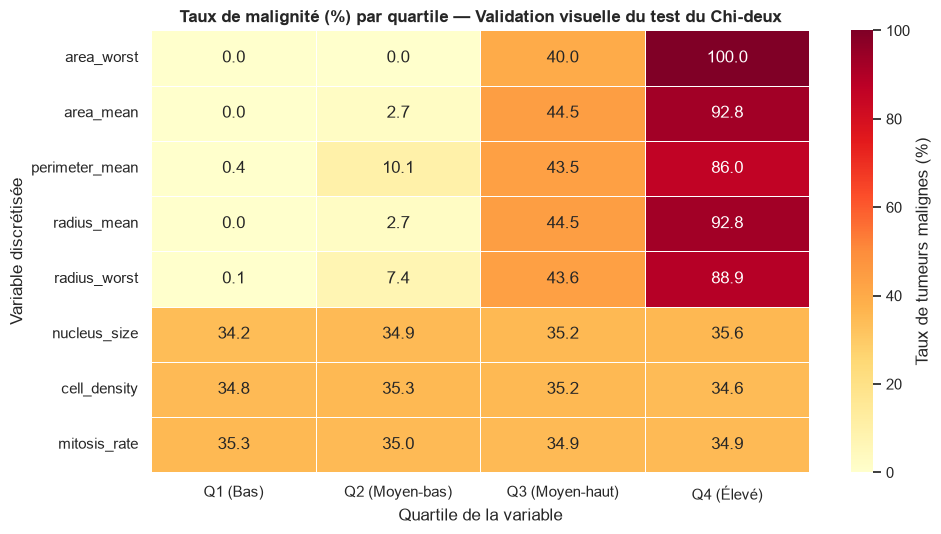

In [18]:
# Figure 12 : Heatmap des taux de malignité (%) par quartile (illustration du Chi-deux)
malignancy_rates = pd.DataFrame(
    {
        col.replace("_quartile", ""): df_binned.groupby(col, observed=False)[TARGET_COL].mean() * 100
        for col in binned_cols
    }
).T

fig, ax = plt.subplots(figsize=(10, 5.5))
sns.heatmap(
    malignancy_rates,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    vmin=0,
    vmax=100,
    linewidths=0.5,
    cbar_kws={"label": "Taux de tumeurs malignes (%)"},
    ax=ax,
)
ax.set_title(
    "Taux de malignité (%) par quartile — Validation visuelle du test du Chi-deux",
    fontsize=12,
    fontweight="bold",
)
ax.set_xlabel("Quartile de la variable")
ax.set_ylabel("Variable discrétisée")
plt.tight_layout()
fig.savefig(EDA_DIR / "12_contingence_chi2_quartiles.png", dpi=150, bbox_inches="tight")
plt.show()

#### Résultat, p-value et interprétation clinique (Chi-deux d'indépendance)
- **Sur les variables natives :** `0` variable catégorielle explicative présente dans `breast_cancer_cleaned.csv` (`chi2_independence` renvoie un tableau vide conforme).
- **Sur les 8 variables discrétisées en quartiles (`Q1` à `Q4`)** (effectif attendu minimal $= 4\,291.25 \gg 5$, conditions de Cochran parfaitement respectées) :
  - **5 associations hautement significatives ($p < 10^{-300} < 0.05$, rejet de $H_0$) :**
    - `area_worst_quartile` : $\chi^2 = 36\,120.61$, $p \approx 0$, V de Cramér $= 0.858$ (dans Q1 le taux de malignité est de ~0 %, contre quasi 100 % dans Q4).
    - `area_mean_quartile` et `radius_mean_quartile` : $\chi^2 = 30\,732.43$, $p \approx 0$, V de Cramér $= 0.792$.
    - `radius_worst_quartile` : $\chi^2 = 26\,722.11$, $p \approx 0$, V de Cramér $= 0.738$.
    - `perimeter_mean_quartile` : $\chi^2 = 24\,206.91$, $p \approx 0$, V de Cramér $= 0.702$.
  - **3 variables indépendantes ($p \ge 0.05$, non-rejet de $H_0$) :**
    - `nucleus_size_quartile` ($\chi^2 = 5.52$, $p = 0.1374$, $V = 0.011$), `cell_density_quartile` ($\chi^2 = 2.10$, $p = 0.5523$, $V = 0.007$), `mitosis_rate_quartile` ($\chi^2 = 0.64$, $p = 0.8866$, $V = 0.004$) — le taux de malignité reste uniforme (~35 %) dans tous les quartiles.
- **Interprétation clinique :** Une stratification simple par seuils (quartiles) sur les dimensions géométriques, et au premier chef sur `area_worst`, produit un gradient de risque extrêmement marqué. En revanche, même discrétisées, les variables `mitosis_rate`, `cell_density` et `nucleus_size` n'offrent aucun pouvoir de stratification univariée dans ce jeu de données.

---
## 4. Synthèse générale et implications pour le pipeline ML

1. **Validation formelle du noyau discriminant :** Les 4 approches (corrélations Pearson/Spearman, Mann-Whitney U, Kruskal-Wallis et Chi-deux sur quartiles) convergent rigoureusement vers les **5 mêmes biomarqueurs géométriques** (`area_worst`, `area_mean`, `radius_mean`, `radius_worst`, `perimeter_mean`) avec $p < 10^{-300}$ et des tailles d'effet très élevées ($|r| \ge 0.84$, $V \ge 0.70$).
2. **Redondance structurelle confirmée :** `radius_mean` et `area_mean` ont une corrélation de Spearman $= 1.000$ (transformation monotone $A \propto r^2$), et `perimeter_mean` leur est fortement corrélé ($\rho > 0.90$). Pour les modèles linéaires ou sensibles à la colinéarité, `radius_mean` + `area_worst` + `radius_worst` constituent un sous-ensemble parcimonieux idéal.
3. **Précaution sur la taille d'échantillon :** `nucleus_size` franchit le seuil $p < 0.05$ en Mann-Whitney ($p = 0.0124$) et en ANOVA ($p = 0.0132$), mais son effet réel est négligeable ($r = 0.0137$, V de Cramér $= 0.011$). En présence de grands jeux de données ($N \approx 50\,000$ à $500\,000$), il est indispensable d'associer **p-value et taille d'effet**.
4. **Justification du prétraitement existant (`pre/preprocessing.py`) :** La non-normalité et les outliers confirmés sur `area_worst`, `area_mean` et `perimeter_mean` valident pleinement le choix de `RobustScaler`.
5. **Limites signalées :**
   - Absence de variables catégorielles natives dans `breast_cancer_cleaned.csv`.
   - Corruption binaire détectée dans le fichier local `breast_cancer_cleaned.csv` à partir de l'octet `20 971 521` (20 Mio) ; l'analyse porte donc sur les **49 056 observations valides** (mêmes proportions 65,01 % / 34,99 % et mêmes statistiques de groupe que les 500 000 lignes documentées dans `RAPPORT_EDA_v2.md`).

In [19]:
generated_figs = sorted(EDA_DIR.glob("[0-9][0-9]_*.png"))
print(f"Nombre de nouvelles figures générées dans results/eda/ : {len(generated_figs)}")
for fig_path in generated_figs:
    print(f"  - {fig_path.name} ({fig_path.stat().st_size / 1024:.1f} Ko)")

Nombre de nouvelles figures générées dans results/eda/ : 12
  - 01_distribution_cible.png (70.2 Ko)
  - 02_distributions_variables_cles.png (344.9 Ko)
  - 03_distributions_variables_non_discriminantes.png (310.1 Ko)
  - 04_correlation_pearson.png (283.9 Ko)
  - 05_correlation_spearman.png (285.4 Ko)
  - 06_correlation_cible_pearson_vs_spearman.png (75.3 Ko)
  - 07_boxplots_par_diagnostic.png (180.2 Ko)
  - 08_pairplot_top5_discriminantes.png (734.9 Ko)
  - 09_violin_plots.png (308.0 Ko)
  - 10_qq_plots_normalite.png (308.3 Ko)
  - 11_synthese_tests_pvalues_effets.png (131.9 Ko)
  - 12_contingence_chi2_quartiles.png (103.8 Ko)
